In [3]:
import torch
from torchvision import datasets, transforms
import torch.nn.functional as F
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

In [4]:
torch.set_default_device("cuda" if torch.cuda.is_available() else "cpu")

In [5]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)
test_dataset = datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

In [6]:
print("Training samples:", len(train_dataset))
print("Test samples:", len(test_dataset))

Training samples: 60000
Test samples: 10000


In [7]:
Xtr = train_dataset.data.float() / 255.0
Xtr = Xtr.reshape(-1, 784)
Ytr = train_dataset.targets

In [8]:
device = torch.get_default_device()
Xtr = Xtr.to(device)
Ytr = Ytr.to(device)

g = torch.Generator().manual_seed(42)
ix = torch.randperm(len(Xtr), generator=g, device="cpu").to(device)

Xval, Yval = Xtr[ix[50000:]], Ytr[ix[50000:]]
Xtr, Ytr = Xtr[ix[:50000]], Ytr[ix[:50000]]

Xtest = (test_dataset.data.float() / 255.0).flatten(start_dim=1).to(device)
Ytest = test_dataset.targets.to(device)

In [9]:
for x, y in [(Xtr, Ytr), (Xval, Yval), (Xtest, Ytest)]:
    print(x.shape, y.shape, x.device)

torch.Size([50000, 784]) torch.Size([50000]) cuda:0
torch.Size([10000, 784]) torch.Size([10000]) cuda:0
torch.Size([10000, 784]) torch.Size([10000]) cuda:0


In [10]:
class Linear:
  
  def __init__(self, fan_in, fan_out, bias=True):
    self.weight = torch.randn((fan_in, fan_out)) / fan_in**0.5 
    self.bias = torch.zeros(fan_out) if bias else None
  
  def __call__(self, x):
    self.out = x @ self.weight
    if self.bias is not None:
      self.out += self.bias
    return self.out
  
  def parameters(self):
    return [self.weight] + ([] if self.bias is None else [self.bias])

class BatchNorm1d:
  
  def __init__(self, dim, eps=1e-5, momentum=0.1):
    self.eps = eps
    self.momentum = momentum
    self.training = True
    self.gamma = torch.ones(dim)
    self.beta = torch.zeros(dim)
    self.running_mean = torch.zeros(dim)
    self.running_var = torch.ones(dim)
  
  def __call__(self, x):
    if self.training:
      if x.ndim == 2:
        dim = 0
      elif x.ndim == 3:
        dim = (0,1)
      xmean = x.mean(dim, keepdim=True) 
      xvar = x.var(dim, keepdim=True)
    else:
      xmean = self.running_mean
      xvar = self.running_var
    xhat = (x - xmean) / torch.sqrt(xvar + self.eps) 
    self.out = self.gamma * xhat + self.beta
    if self.training:
      with torch.no_grad():
        self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean
        self.running_var = (1 - self.momentum) * self.running_var + self.momentum * xvar
    return self.out
  
  def parameters(self):
    return [self.gamma, self.beta]

class Tanh:
  def __call__(self, x):
    self.out = torch.tanh(x)
    return self.out
  def parameters(self):
    return []

class Embedding:
  
  def __init__(self, num_embeddings, embedding_dim):
    self.weight = torch.randn((num_embeddings, embedding_dim))
    
  def __call__(self, IX):
    self.out = self.weight[IX]
    return self.out
  
  def parameters(self):
    return [self.weight]

class FlattenConsecutive:

    def __init__(self, n):
        self.n = n
  
    def __call__(self, x):
        B, T, C = x.shape
        x = x.view(B, T // self.n, C*self.n)
        if x.shape[1] == 1:
            x = x.squeeze(1)
        self.out = x
        return self.out

    def parameters(self):
        return []

class Sequential: 
    
    def __init__(self, layers):
        self.layers = layers

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        self.out = x
        return self.out

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

class ResidualBlock:

    def __init__(self, fan_in, expansion=2):
        self.layers = Sequential([
            Linear(fan_in, fan_in * expansion),
            Tanh(),
            Linear(fan_in * expansion, fan_in),
        ])

    def __call__(self, x):
        return x + self.layers(x)

    def parameters(self):
        return self.layers.parameters()

In [11]:
n_in = Xtr[0].numel()         
n_out = len(torch.unique(Ytr)) 
n_h = 128

In [12]:
print(n_in)
print(n_out)

784
10


In [21]:
model = Sequential([
    Linear(n_in, n_h, bias=False),
    BatchNorm1d(n_h),
    Tanh(),

    ResidualBlock(n_h),
    ResidualBlock(n_h),
    ResidualBlock(n_h),

    Linear(n_h, n_out),
])

with torch.no_grad():
    model.layers[-1].weight *= 0.1

parameters = model.parameters()

for p in parameters:
    p.requires_grad = True

In [22]:
batch_size = 256
max_steps = 6000
learning_rate = 0.01

lossi = []

In [23]:
for i in range(max_steps):

    ix = torch.randint(0, Xtr.shape[0], (batch_size,))
    Xb, Yb = Xtr[ix], Ytr[ix]

    logits = model(Xb)
    loss = F.cross_entropy(logits, Yb)

    for p in parameters:
        p.grad = None

    loss.backward()

    lr = learning_rate if i < 4000 else learning_rate * 0.1

    with torch.no_grad():
        for p in parameters:
            p += -lr * p.grad

    if i % 200 == 0:
        print(f'{i:5d}/{max_steps}: {loss.item():.4f}')

    lossi.append(loss.detach())


    0/6000: 2.2943
  200/6000: 0.4133
  400/6000: 0.4358
  600/6000: 0.3186
  800/6000: 0.2998
 1000/6000: 0.2464
 1200/6000: 0.1848
 1400/6000: 0.3239
 1600/6000: 0.2720
 1800/6000: 0.2461
 2000/6000: 0.2083
 2200/6000: 0.1865
 2400/6000: 0.1988
 2600/6000: 0.0838
 2800/6000: 0.2471
 3000/6000: 0.1479
 3200/6000: 0.1187
 3400/6000: 0.1374
 3600/6000: 0.1123
 3800/6000: 0.1446
 4000/6000: 0.1065
 4200/6000: 0.1417
 4400/6000: 0.1062
 4600/6000: 0.1300
 4800/6000: 0.0919
 5000/6000: 0.1288
 5200/6000: 0.1218
 5400/6000: 0.1174
 5600/6000: 0.0933
 5800/6000: 0.0806


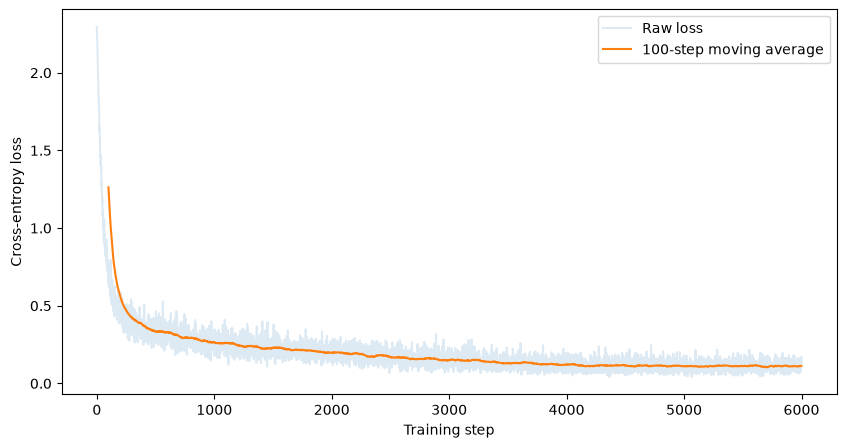

In [24]:
losses = torch.stack(lossi).cpu().numpy()

smoothed = pd.Series(losses).rolling(window=100).mean()

plt.figure(figsize=(10, 5))
plt.plot(losses, alpha=0.15, label="Raw loss")
plt.plot(smoothed, label="100-step moving average")
plt.xlabel("Training step")
plt.ylabel("Cross-entropy loss")
plt.legend()
plt.show()

In [25]:
for layer in model.layers:
    layer.training = False

In [26]:
@torch.no_grad()
def split_loss(split):
    x, y = {
        'train': (Xtr, Ytr),
        'val': (Xval, Yval),
        'test': (Xtest, Ytest),
    }[split]

    logits = model(x)

    loss = F.cross_entropy(logits, y)
    accuracy = (logits.argmax(dim=1) == y).float().mean()

    print(f'{split}: loss={loss.item():.4f}, accuracy={accuracy.item():.4f}')

In [27]:
split_loss('train')
split_loss('val')
split_loss('test')

train: loss=0.1067, accuracy=0.9710
val: loss=0.1678, accuracy=0.9525
test: loss=0.1476, accuracy=0.9550
